In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sns.set_style("whitegrid")
OUT_DIR = "outputs"
import os; os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42

online_retail = fetch_ucirepo(id=352)
df_raw = online_retail.data.original.copy()

for col in ["Unnamed: 0", "index", ""]:
    if col in df_raw.columns:
        df_raw = df_raw.drop(columns=[col])

df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"], errors="coerce")
df_raw["CustomerID"]  = pd.to_numeric(df_raw["CustomerID"], errors="coerce").astype("Int64")
df_raw["InvoiceNo"]   = df_raw["InvoiceNo"].astype(str)
df_raw["StockCode"]   = df_raw["StockCode"].astype(str)
df_raw["Quantity"]    = pd.to_numeric(df_raw["Quantity"], errors="coerce")
df_raw["UnitPrice"]   = pd.to_numeric(df_raw["UnitPrice"], errors="coerce")

print("Raw:", df_raw.shape)

Raw: (541909, 8)


سؤال ۱ : حداقل دو ویژگی را انتخاب کنید که احتمال می‌دهید برای مدل‌سازی مفید نباشند + دلایل.

Description: متن آزاد، ~۴,۲۲۰ مقدار یکتا، بدون ساختار؛ در هیچ ویژگی مهندسی‌شده استفاده نشد و در مدل نقش ندارد.
Country : طبق EDA، ~۹۱٪ تراکنش‌ها از بریتانیا است. واریانس بسیار پایین و کاردینالیتی ~۳۸ دسته، سیگنال ضعیف برای مدل. در پروژه ما وارد مدل نشد.

سؤال ۲ : نسخه جدید دیتاست فقط با ویژگی‌های منتخب


In [2]:
selected_df = df_raw.drop(columns=["Description", "Country"]).copy()

print("selected_df shape:", selected_df.shape)
print("Columns:", selected_df.columns.tolist())
print(selected_df.head())

selected_df shape: (541909, 6)
Columns: ['InvoiceNo', 'StockCode', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID']
  InvoiceNo StockCode  Quantity         InvoiceDate  UnitPrice  CustomerID
0    536365    85123A         6 2010-12-01 08:26:00       2.55       17850
1    536365     71053         6 2010-12-01 08:26:00       3.39       17850
2    536365    84406B         8 2010-12-01 08:26:00       2.75       17850
3    536365    84029G         6 2010-12-01 08:26:00       3.39       17850
4    536365    84029E         6 2010-12-01 08:26:00       3.39       17850


سؤال ۳ : مقایسه تعداد ویژگی‌ها قبل و بعد.


In [3]:
print(f"قبل از Selection: {df_raw.shape[1]} ستون")
print(f"بعد از Selection: {selected_df.shape[1]} ستون")
print(f"تعداد حذف‌شده: {df_raw.shape[1] - selected_df.shape[1]}")

قبل از Selection: 8 ستون
بعد از Selection: 6 ستون
تعداد حذف‌شده: 2


سوال ۴ : برسی تعداد و درصد مقادیر خالی

In [4]:
null_table = pd.DataFrame({
    "Column": selected_df.columns,
    "Null_Count": selected_df.isnull().sum().values,
    "Null_Percent": (selected_df.isnull().sum() / len(selected_df) * 100).round(2).values,
}).sort_values("Null_Count", ascending=False)
print(null_table.to_string(index=False))

     Column  Null_Count  Null_Percent
 CustomerID      135080         24.93
  InvoiceNo           0          0.00
  StockCode           0          0.00
   Quantity           0          0.00
InvoiceDate           0          0.00
  UnitPrice           0          0.00


سؤال ۵ : سه روش برای پر کردن داده گمشده.
روش ۱ — حذف رکوردها: رکوردهای فاقد CustomerID را از تحلیل مشتری حذف می‌کنیم (اما از df_raw حذف نمی‌کنیم تا در تحلیل کلان باقی بمانند).
روش ۲ — Imputation با دسته «UNKNOWN»: یک شناسه ساختگی (مثلاً -1) به همه گمشده‌ها بدهیم. مشکل: یک «مشتری جعلی» با هزاران تراکنش می‌سازد که K-Means و برچسب‌گذاری را آلوده می‌کند.
روش ۳ — Imputation مدل‌محور: پیش‌بینی CustomerID از روی InvoiceNo، Country، StockCode. غیرمنطقی، چون CustomerID یک شناسه است، نه کمیت قابل پیش‌بینی.

تحلیل: CustomerID شناسه است، نه یک ویژگی عددی یا دسته‌ای معمولی. Imputation برای شناسه‌ها معنا ندارد و فقط داده را آلوده می‌کند.

سؤال ۶ : انتخاب و پیاده‌سازی یکی از روش‌ها.


In [6]:
selected_no_na = selected_df.dropna(subset=["CustomerID"]).copy()

print(f"قبل: {len(selected_df):,} رکورد")
print(f"بعد: {len(selected_no_na):,} رکورد")
print(f"حذف‌شده: {len(selected_df) - len(selected_no_na):,}")
print(f"df_raw همچنان دست‌نخورده: {df_raw.shape}")

قبل: 541,909 رکورد
بعد: 406,829 رکورد
حذف‌شده: 135,080
df_raw همچنان دست‌نخورده: (541909, 8)


سؤال ۷ : شناسایی رکوردهای تکراری.


In [7]:
dup_mask = selected_no_na.duplicated(keep=False)
dup_count = selected_no_na.duplicated().sum()
print(f"تعداد رکوردهای تکراری: {dup_count:,}")
print(f"درصد: {dup_count / len(selected_no_na) * 100:.3f}%")
print(f"نمونه تکراری‌ها:\n{selected_no_na[dup_mask].head(6)}")

تعداد رکوردهای تکراری: 5,227
درصد: 1.285%
نمونه تکراری‌ها:
    InvoiceNo StockCode  Quantity         InvoiceDate  UnitPrice  CustomerID
485    536409     22111         1 2010-12-01 11:45:00       4.95       17908
489    536409     22866         1 2010-12-01 11:45:00       2.10       17908
494    536409     21866         1 2010-12-01 11:45:00       1.25       17908
517    536409     21866         1 2010-12-01 11:45:00       1.25       17908
521    536409     22900         1 2010-12-01 11:45:00       2.95       17908
527    536409     22866         1 2010-12-01 11:45:00       2.10       17908


سؤال ۸ : نسخه بدون رکورد تکراری.


In [8]:
selected_dedup = selected_no_na.drop_duplicates().copy()

print(f"قبل: {len(selected_no_na):,}")
print(f"بعد: {len(selected_dedup):,}")
print(f"حذف‌شده: {len(selected_no_na) - len(selected_dedup):,}")

قبل: 406,829
بعد: 401,602
حذف‌شده: 5,227


سوال ۹ : شناسایی داده های پرت

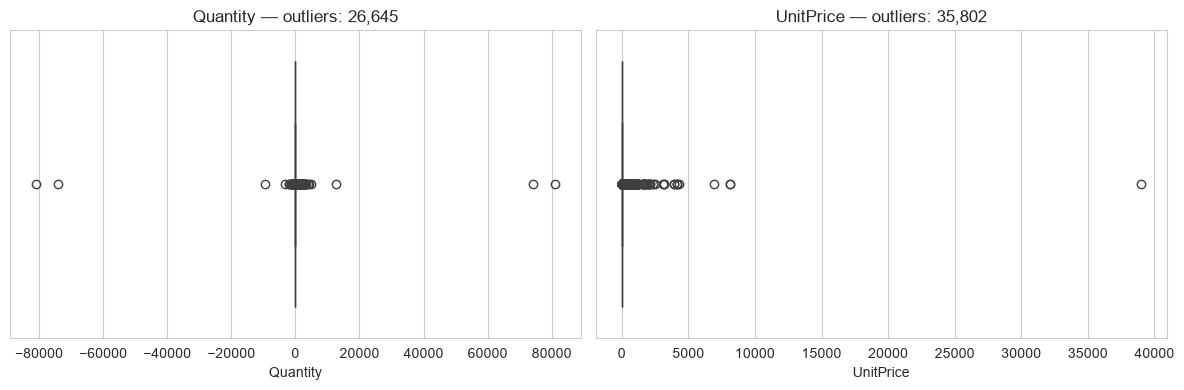

{'Quantity': {'count': 26645, 'lo': -13.0, 'hi': 27.0}, 'UnitPrice': {'count': 35802, 'lo': -2.5, 'hi': 7.5}}


In [10]:
num_cols = ["Quantity", "UnitPrice"]

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((series < lo) | (series > hi)), lo, hi

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
outlier_info = {}
for ax, col in zip(axes, num_cols):
    mask, lo, hi = iqr_outliers(selected_dedup[col])
    outlier_info[col] = {"count": int(mask.sum()), "lo": lo, "hi": hi}
    sns.boxplot(x=selected_dedup[col], ax=ax)
    ax.set_title(f"{col} — outliers: {mask.sum():,}")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/dp_boxplot_outliers.png", dpi=120)
plt.show()

print(outlier_info)

سوال ۱۰ : جدول و تعداد داده های پرت

In [11]:
outlier_df = pd.DataFrame([
    {"Feature": col, "Number_of_Outliers": info["count"],
     "Lower_Bound": round(info["lo"], 2), "Upper_Bound": round(info["hi"], 2)}
    for col, info in outlier_info.items()
])
print(outlier_df.to_string(index=False))
outlier_df.to_csv(f"{OUT_DIR}/dp_outliers.csv", index=False)

  Feature  Number_of_Outliers  Lower_Bound  Upper_Bound
 Quantity               26645        -13.0         27.0
UnitPrice               35802         -2.5          7.5


سؤال ۱۱ : انتخاب و پیاده‌سازی استراتژی برای داده های پرت

In [12]:
selected_dedup = selected_dedup.copy()
selected_dedup["IsCancelled"] = selected_dedup["InvoiceNo"].str.startswith("C")
selected_dedup["IsReturn"]    = (selected_dedup["Quantity"] < 0) & (~selected_dedup["IsCancelled"])

df_valid = selected_dedup[
    (~selected_dedup["IsCancelled"]) &
    (selected_dedup["Quantity"] > 0) &
    (selected_dedup["UnitPrice"] > 0)
].copy()
df_valid["TotalPrice"] = df_valid["Quantity"] * df_valid["UnitPrice"]

print(f"کل تراکنش‌های پاک: {len(selected_dedup):,}")
print(f"خرید معتبر: {len(df_valid):,}")
print(f"لغو: {selected_dedup['IsCancelled'].sum():,}")
print(f"مرجوعی: {selected_dedup['IsReturn'].sum():,}")

کل تراکنش‌های پاک: 401,602
خرید معتبر: 392,690
لغو: 8,872
مرجوعی: 0


سؤال ۱۲ : حداقل دو ویژگی جدید با توضیح کسب‌وکاری.


In [ ]:
OBS_DAYS = 180
REF_DATE = pd.Timestamp("2011-09-01")
obs_start = REF_DATE - pd.Timedelta(days=OBS_DAYS)

obs = df_valid[(df_valid["InvoiceDate"] >= obs_start) &
               (df_valid["InvoiceDate"] < REF_DATE)].copy()

rfm = obs.groupby("CustomerID").agg(
    Recency          = ("InvoiceDate", lambda x: (REF_DATE - x.max()).days),
    Frequency        = ("InvoiceNo", "nunique"),
    Monetary         = ("TotalPrice", "sum"),
    FirstPurchase    = ("InvoiceDate", "min"),
    LastPurchase     = ("InvoiceDate", "max"),
    DistinctProducts = ("StockCode", "nunique"),
    ActiveDays       = ("InvoiceDate", lambda x: x.dt.normalize().nunique()),
    TotalRows        = ("InvoiceNo", "size"),
).reset_index()

rfm["TenureDays"]        = (REF_DATE - rfm["FirstPurchase"]).dt.days
rfm["First_last_span"]   = (rfm["LastPurchase"] - rfm["FirstPurchase"]).dt.days
rfm["AvgOrderValue"]     = rfm["Monetary"] / rfm["Frequency"]
rfm["Product_diversity"] = rfm["DistinctProducts"] / rfm["TotalRows"]

mid = REF_DATE - pd.Timedelta(days=OBS_DAYS // 2)
f1 = obs[obs["InvoiceDate"] <  mid].groupby("CustomerID").agg(F1=("InvoiceNo","nunique"), M1=("TotalPrice","sum"))
f2 = obs[obs["InvoiceDate"] >= mid].groupby("CustomerID").agg(F2=("InvoiceNo","nunique"), M2=("TotalPrice","sum"))
change = f1.join(f2, how="outer").fillna(0)
change["Freq_change"]     = change["F2"] - change["F1"]
change["Monetary_change"] = change["M2"] - change["M1"]

rfm = rfm.merge(change.reset_index()[["CustomerID","Freq_change","Monetary_change"]],
                on="CustomerID", how="left").fillna({"Freq_change":0,"Monetary_change":0})

raw_obs = selected_dedup[(selected_dedup["InvoiceDate"] >= obs_start) &
                         (selected_dedup["InvoiceDate"] < REF_DATE)].copy()
total_inv = raw_obs.groupby("CustomerID")["InvoiceNo"].nunique().rename("TotalInvoices")
cancels   = raw_obs[raw_obs["IsCancelled"]].groupby("CustomerID")["InvoiceNo"].nunique().rename("CancelCount")
returns   = raw_obs[raw_obs["IsReturn"]].groupby("CustomerID").size().rename("ReturnCount")
rates = pd.concat([total_inv, cancels, returns], axis=1).fillna(0)
rates["Cancel_rate"] = rates["CancelCount"] / rates["TotalInvoices"].replace(0, np.nan)
rates["Return_rate"] = rates["ReturnCount"] / rates["TotalInvoices"].replace(0, np.nan)
rfm = rfm.merge(rates.reset_index()[["CustomerID","Cancel_rate","Return_rate"]],
                on="CustomerID", how="left")
rfm[["Cancel_rate","Return_rate"]] = rfm[["Cancel_rate","Return_rate"]].fillna(0)

print("Features built:", rfm.shape)

Features built: (2772, 17)


سؤال ۲۱: ساخت DataFrame آزمایشی.


In [ ]:
crm_data = pd.DataFrame({
    "CustomerID": [12346, 12347, 12348, 12349, 12350, 99999],
    "Last_Campaign": ["Discount10", "None", "Email", "Discount10", "SMS", "None"],
    "Response_Rate": [0.15, 0.02, 0.08, 0.12, 0.05, 0.01],
    "Total_Contacts_Last_Year": [3, 1, 2, 4, 2, 0],
})
print(crm_data)

   CustomerID Last_Campaign  Response_Rate  Total_Contacts_Last_Year
0       12346    Discount10           0.15                         3
1       12347          None           0.02                         1
2       12348         Email           0.08                         2
3       12349    Discount10           0.12                         4
4       12350           SMS           0.05                         2
5       99999          None           0.01                         0


سؤال ۲۲: کلید مشترک.

کلید مشترک: CustomerID. هر دو دیتاست (ویژگی‌های مشتری و CRM) این ستون را دارند و هر مقدار یکتا به یک مشتری اشاره می‌کند.



سؤال ۲۳: انجام Merge.


In [16]:
customer_features = rfm.copy()   # از Q19
merged_df = customer_features.merge(crm_data, on="CustomerID", how="left")

print(f"قبل از merge: {len(customer_features):,}")
print(f"بعد از merge: {len(merged_df):,}")
print(f"ستون‌ها: {merged_df.shape[1]}")

قبل از merge: 2,772
بعد از merge: 2,772
ستون‌ها: 20


سؤال ۲۴: مقایسه انواع Merge.


In [17]:
for how in ["inner", "left", "right", "outer"]:
    m = customer_features.merge(crm_data, on="CustomerID", how=how)
    print(f"{how:6s} → rows: {len(m):,}, NaN در Response_Rate: {m['Response_Rate'].isna().sum()}")

inner  → rows: 2, NaN در Response_Rate: 0
left   → rows: 2,772, NaN در Response_Rate: 2770
right  → rows: 6, NaN در Response_Rate: 0
outer  → rows: 2,776, NaN در Response_Rate: 2770


سؤال ۲۵: کدام Merge مناسب‌تر است؟


In [18]:
merged_df = customer_features.merge(crm_data, on="CustomerID", how="left")
merged_df["Last_Campaign"] = merged_df["Last_Campaign"].fillna("None")
for c in ["Response_Rate", "Total_Contacts_Last_Year"]:
    merged_df[c] = merged_df[c].fillna(0)

print("NaN پس از merge و پرکردن:")
print(merged_df.isnull().sum().sum(), "NaN باقی مانده")

NaN پس از merge و پرکردن:
0 NaN باقی مانده


سؤال ۲۶: بررسی نوع داده تمام ستون‌ها.


In [19]:
print("=== نوع داده‌های ویژگی‌های مشتری ===")
dtype_df = pd.DataFrame({
    "Column": customer_features.columns,
    "Dtype": customer_features.dtypes.astype(str).values,
})
print(dtype_df.to_string(index=False))

=== نوع داده‌های ویژگی‌های مشتری ===
           Column          Dtype
       CustomerID          Int64
          Recency          int64
        Frequency          int64
         Monetary        float64
    FirstPurchase datetime64[us]
     LastPurchase datetime64[us]
 DistinctProducts          int64
       ActiveDays          int64
        TotalRows          int64
       TenureDays          int64
  First_last_span          int64
    AvgOrderValue        float64
Product_diversity        float64
      Freq_change        float64
  Monetary_change        float64
      Cancel_rate        float64
      Return_rate        float64


سؤال ۲۸: اعمال Datatype مناسب.
